# DOA 합성 실험 — 대역 상한과 PHAT에 쓰는 칸

> 2026-10-27 · 계산 도구 [`doa/mask_phat.py`](../doa/mask_phat.py) · 커널: `Tools/.venv`
> 이 노트북은 **실험의 흐름**을 단계별로 보여 준다. 결론은 마지막 절에 **결론 후보**로만 적고, 사용자가 확인한 뒤에 결정으로 올린다.

**질문 두 개**
1. 방위 계산 대역의 상한을 3000 Hz에서 2400 Hz로 내리면 유효율과 오차가 어떻게 바뀌나? (공간 앨리어싱 한계 2450 Hz 때문에 나온 제안)
2. PHAT에서 대역 안 칸 전부가 아니라 **고조파 칸만** 투표하게 하면 어떻게 되나?

**조건** — 보드와 같은 계산(`doa_stream`, `doa.h`와 같은 숫자)을 쓰고, 신호만 합성이다.

| 항목 | 값 |
|---|---|
| 배열 | 70 mm 정삼각형, 12,500 Hz |
| 창 | 0.5 s 관측, 0.25 s 이동, 블록 512 / NFFT 1024 (칸 하나 = 12.2 Hz) |
| 유효 판정 | 세 쌍 최소 피크 ≥ 0.15, \|닫힘\| ≤ 0.3샘플, 0.5 ≤ norm ≤ 1.3 |
| 잡음 | 채널마다 독립 백색 잡음. SNR = 300 ~ 3000 Hz 대역 전력비 |
| 한계 | 반사 없음, 고도 0°, 배경에 선(팬·험) 없음 → 실제보다 쉬운 조건 |


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join("..", "doa")))
import numpy as np
import matplotlib.pyplot as plt
import mask_phat as mp
import doa_stream as ds
import gcc_phat as g
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 90; plt.rcParams["mathtext.fontset"] = "dejavusans"

def table(rows, keys, heads=None):
    heads = heads or keys
    w = [max(len(str(h)), 8) for h in heads]
    print(" | ".join(str(h).ljust(n) for h, n in zip(heads, w)))
    for r in rows:
        print(" | ".join((f"{r[k]:.2f}" if isinstance(r[k], float) else str(r[k])).ljust(n) for k, n in zip(keys, w)))

## 1. 배열과 정답 지연

소리는 마이크마다 조금씩 다른 시각에 도착한다. 그 **도착 시간차(지연)**가 방향의 단서다.

- 가장 큰 지연 = 간격 ÷ 음속 = 0.07 m ÷ 343 m/s = 0.204 ms → × 12,500 Hz = **2.55샘플**
- 공간 앨리어싱 한계 = 음속 ÷ (2 × 간격) = 343 ÷ 0.14 = **2450 Hz**. 이 주파수에서 지연 2.55샘플이면 위상차가 정확히 반 바퀴(180°)다.

간격 70.0 mm, 최대 지연 2.55 샘플, c/(2d) = 2450 Hz


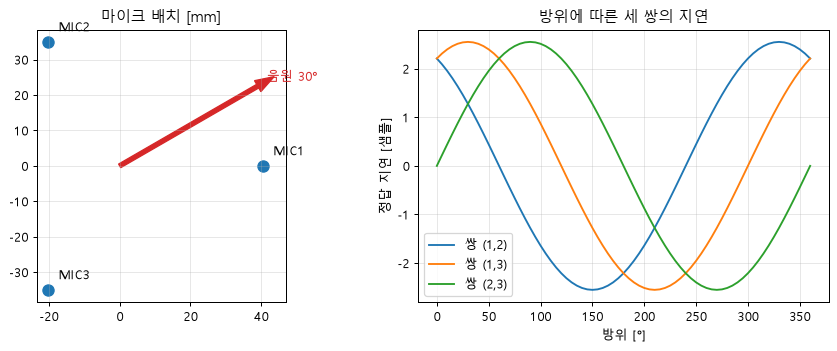

방위 30°의 정답 지연 [샘플]: [1.276 2.551 1.276]


In [2]:
print(f"간격 {mp.D*1000:.1f} mm, 최대 지연 {mp.D/mp.C*mp.FS:.2f} 샘플, c/(2d) = {mp.F_ALIAS:.0f} Hz")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(mp.POS[:, 0]*1000, mp.POS[:, 1]*1000, s=80)
for i, p in enumerate(mp.POS):
    ax[0].annotate(f"MIC{i+1}", p*1000 + 3)
az = 30
ax[0].arrow(0, 0, 45*np.cos(np.radians(az)), 45*np.sin(np.radians(az)), width=1.2, color="C3")
ax[0].text(48*np.cos(np.radians(az)), 48*np.sin(np.radians(az)), f"음원 {az}°", color="C3")
ax[0].set_aspect("equal"); ax[0].set_title("마이크 배치 [mm]"); ax[0].grid(alpha=.3)
azs = np.arange(0, 361, 5)
T = np.array([mp.true_tau(a) for a in azs])
for k, (i, j) in enumerate(g.PAIRS):
    ax[1].plot(azs, T[:, k], label=f"쌍 ({i+1},{j+1})")
ax[1].set_xlabel("방위 [°]"); ax[1].set_ylabel("정답 지연 [샘플]"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title("방위에 따른 세 쌍의 지연")
plt.tight_layout(); plt.show()
print("방위 30°의 정답 지연 [샘플]:", np.round(mp.true_tau(30), 3))

## 2. 음원 두 종류의 스펙트럼

**스펙트럼**은 소리를 주파수별 세기로 나눠 본 그림이다.

- **고조파 음원**: 기본음 f0의 정수배(f0, 2f0, 3f0 …)에만 에너지가 있다. 엔진·모터 소리가 이렇다. 여기서는 400 Hz × 1 ~ 7 (400 ~ 2800 Hz).
- **넓은 대역 음원**: 300 ~ 3000 Hz 전체에 고르게 퍼진 잡음. 바람 소리·프로펠러 쉭 소리에 가깝다.

두 음원 모두 방위 30°, SNR 6 dB.

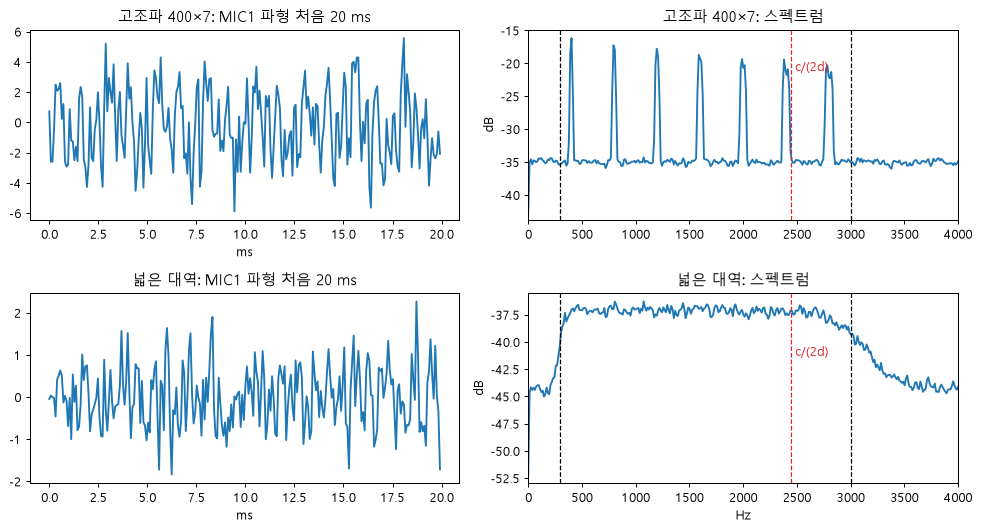

In [3]:
from scipy.signal import welch
scenes = {n: mp.make_scene(n, 30, 6) for n in ("고조파 400×7", "넓은 대역")}
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for r, (n, x) in enumerate(scenes.items()):
    t = np.arange(250) / mp.FS * 1000
    ax[r, 0].plot(t, x[0, :250]); ax[r, 0].set_title(f"{n}: MIC1 파형 처음 20 ms"); ax[r, 0].set_xlabel("ms")
    f, P = welch(x[0], mp.FS, nperseg=1024)
    ax[r, 1].plot(f, 10*np.log10(P)); ax[r, 1].set_xlim(0, 4000); ax[r, 1].set_title(f"{n}: 스펙트럼"); ax[r, 1].set_ylabel("dB")
    for fx, c, lab in ((300, "k", "대역 300"), (3000, "k", "대역 3000"), (mp.F_ALIAS, "C3", "2450")):
        ax[r, 1].axvline(fx, color=c, ls="--", lw=1)
    ax[r, 1].text(mp.F_ALIAS + 30, 10*np.log10(P.max()) - 5, "c/(2d)", color="C3")
ax[1, 1].set_xlabel("Hz"); plt.tight_layout(); plt.show()

## 3. 교차 스펙트럼의 위상 — 지연이 숨어 있는 곳

한 쌍의 마이크에서 칸마다 **위상차**(두 신호가 몇 도 어긋났나)를 본다.

- 지연이 τ샘플이면 주파수 f 칸의 위상차는 −360° × f × τ ÷ 12,500 이다. 주파수에 비례하는 **직선**이다.
- 그런데 위상은 ±180°에서 감긴다. 2450 Hz 위에서는 직선이 ±180°를 넘어 감기므로, 그 칸 하나만 보면 지연을 하나로 정할 수 없다 (공간 앨리어싱).
- 아래 그림: 점 = 측정 위상 (첫 0.5 s 창, 쌍 (1,2)), 선 = 정답 지연이 만드는 위상.

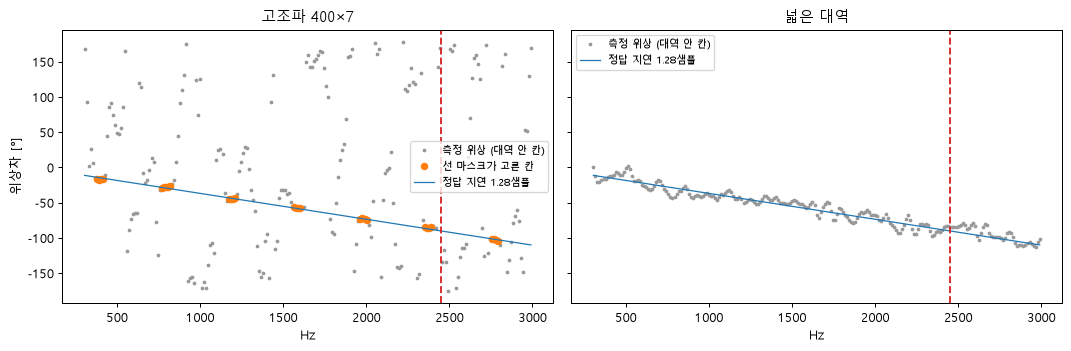

In [4]:
tau0 = mp.true_tau(30)[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (n, x) in zip(ax, scenes.items()):
    S = ds.cross_spectra(x[:, :6250], mp.BLOCK, mp.NFFT)
    inb = (mp.FREQ >= 300) & (mp.FREQ <= 3000)
    ph = np.degrees(np.angle(S[0]))
    a.plot(mp.FREQ[inb], ph[inb], ".", ms=4, color="0.6", label="측정 위상 (대역 안 칸)")
    if n.startswith("고조파"):
        lm = mp.make_mask(S, "line")
        a.plot(mp.FREQ[lm], ph[lm], "o", ms=5, color="C1", label="선 마스크가 고른 칸")
    th = np.degrees(np.angle(np.exp(-2j*np.pi*mp.FREQ*tau0/mp.FS)))
    a.plot(mp.FREQ[inb], th[inb], color="C0", lw=1, label=f"정답 지연 {tau0:.2f}샘플")
    a.axvline(mp.F_ALIAS, color="C3", ls="--"); a.set_title(n); a.set_xlabel("Hz"); a.legend(fontsize=8)
ax[0].set_ylabel("위상차 [°]"); plt.tight_layout(); plt.show()

**보이는 것:** 넓은 대역은 모든 칸이 정답 선 위에 있다. 고조파는 **선이 있는 칸(주황)만** 정답 선 위에 있고, 나머지 회색 칸은 잡음이라 위상이 아무렇게나 흩어진다.

## 4. PHAT 상관 곡선 — 칸들의 투표

**PHAT**은 칸마다 세기를 1로 맞추고 위상만 남긴 뒤, "지연 τ라면 모든 칸의 위상이 얼마나 맞나"를 τ마다 더한다. 곡선의 봉우리 위치가 추정 지연이고, **봉우리 높이 = 투표한 칸 중 그 지연에 동의한 비율**이다 (1이면 전부 동의).

- `full`: 대역 안 221칸 전부 투표 (지금 doa.c).
- `line`: 스펙트럼이 대역 중앙값보다 10 dB 이상 큰 칸만.
- `oracle`: 정답 f0의 배수 ±2칸만.

음원: 고조파 700 Hz × 4 (선 4개), SNR 6 dB, 방위 30°. 가로선 = 유효 문턱 0.15.

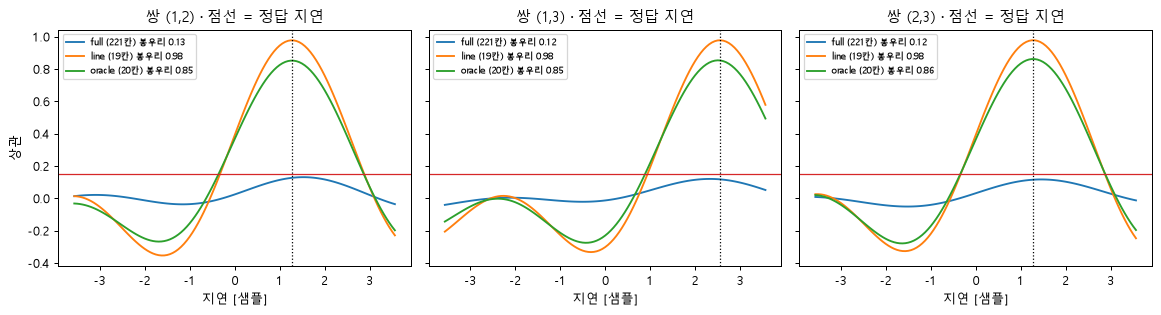

In [5]:
x = mp.make_scene("고조파 700×4", 30, 6)
win = x[:, :6250]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
res = {}
for m in ("full", "line", "oracle"):
    r = mp.estimate(win, m, f0=700, keep=True); res[m] = r
    for k, a in enumerate(ax):
        lags, cc, tau, pk = r["curves"][k]
        a.plot(lags, cc, label=f"{m} ({r['nbins']}칸) 봉우리 {pk:.2f}")
for k, a in enumerate(ax):
    i, j = g.PAIRS[k]
    a.axvline(mp.true_tau(30)[k], color="k", ls=":", lw=1)
    a.axhline(0.15, color="C3", lw=1)
    a.set_title(f"쌍 ({i+1},{j+1}) · 점선 = 정답 지연"); a.set_xlabel("지연 [샘플]"); a.legend(fontsize=7)
ax[0].set_ylabel("상관"); plt.tight_layout(); plt.show()

**보이는 것:** 세 방법 모두 봉우리 **위치**는 정답 근처다. 차이는 **높이**다. `full`은 221칸 중 선 칸이 20개 남짓이라 봉우리가 0.1 근처로 낮고, 문턱 0.15에 걸린다.

## 5. 유효 판정 — 세 조건

한 창의 결과를 믿을지 정하는 세 조건 (doa.h `DOA_MIN_PEAK`, `DOA_MAX_CLOSURE`, `DOA_MIN_NORM`/`MAX_NORM`).

| 조건 | 무엇을 보나 | 문턱 |
|---|---|---|
| ① 피크 | 세 쌍 중 가장 낮은 봉우리. 투표가 한 지연에 몰렸나 | ≥ 0.15 |
| ② 닫힘 | τ12 + τ23 − τ13. 세 지연이 서로 앞뒤가 맞나 (도착 시각 차를 이어 붙이면 0이어야 함) | \|값\| ≤ 0.3샘플 |
| ③ norm | 세 지연으로 푼 방향 벡터의 길이. 평면 위 음원이면 1 근처 | 0.5 ~ 1.3 |

**유효율 = 유효 창 수 ÷ 평가 대상 창 수.** 이 합성은 음원이 늘 있으므로 모든 창이 평가 대상이다 (실제 장치는 배경보다 6 dB 큰 창만).
유효율은 "판정기가 믿었다"는 비율이지 "맞았다"가 아니다. 그래서 정답이 있는 시험에서는 **유효 중 오답률**(유효 창 중 오차 > 10°)을 같이 본다.

In [6]:
print("방법   | 칸 | 피크(세 쌍)        | 닫힘 [샘플] | norm | 유효 | 방위   | 오차")
for m, r in res.items():
    e = float(ds.ang_err(r["angle"], 30))
    print(f"{m:6s} | {r['nbins']:3d} | {np.round(r['peak'], 2)} | {r['closure']:+.3f}      | {r['norm']:.2f} | "
          f"{'예' if r['valid'] else '아니오'}   | {r['angle']:6.1f}° | {e:.1f}°  {'' if r['valid'] else '무효 사유: ' + ','.join(mp.why_invalid(r))}")

방법   | 칸 | 피크(세 쌍)        | 닫힘 [샘플] | norm | 유효 | 방위   | 오차
full   | 221 | [0.13 0.12 0.12] | +0.655      | 1.00 | 아니오   |   29.1° | 0.9°  무효 사유: 피크,닫힘
line   |  19 | [0.98 0.98 0.98] | +0.001      | 1.00 | 예   |   30.0° | 0.0°  
oracle |  20 | [0.85 0.85 0.86] | +0.043      | 0.99 | 예   |   30.0° | 0.0°  


## 6. 창이 이어질 때 — 8초, 31창

같은 음원을 8초 들으면 0.25 s마다 창이 하나씩 나온다. 창마다 방위와 유효 여부를 찍는다. 채운 점 = 유효, 빈 점 = 무효.

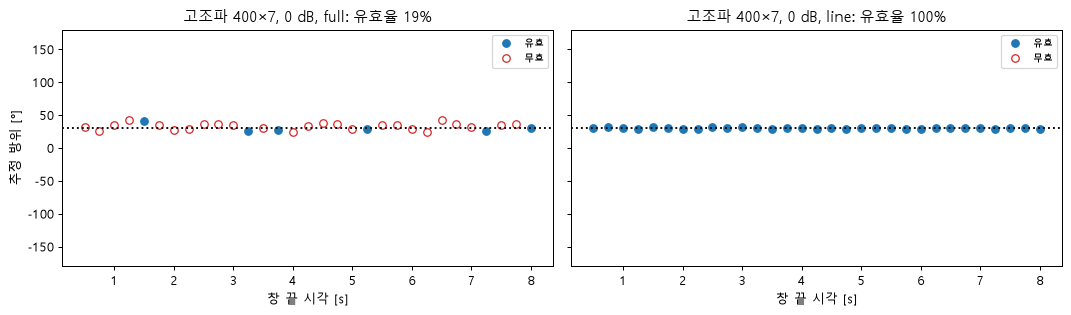

In [7]:
x = mp.make_scene("고조파 400×7", 30, 0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, m in zip(ax, ("full", "line")):
    rs = mp.windows(x, m, 400)
    t = np.arange(len(rs)) * 0.25 + 0.5
    ang = np.array([r["angle"] for r in rs]); v = np.array([r["valid"] for r in rs])
    a.plot(t[v], ang[v], "o", color="C0", label="유효")
    a.plot(t[~v], ang[~v], "o", mfc="none", color="C3", label="무효")
    a.axhline(30, color="k", ls=":"); a.set_ylim(-180, 180)
    a.set_title(f"고조파 400×7, 0 dB, {m}: 유효율 {v.mean()*100:.0f}%"); a.set_xlabel("창 끝 시각 [s]"); a.legend(fontsize=8)
ax[0].set_ylabel("추정 방위 [°]"); plt.tight_layout(); plt.show()

## 7. 질문 1 — 대역 상한 3000 vs 2400 (`full` 방식)

> ▶ **예측 지점 (T1)**: 처음 보는 실험이면 이 아래 셀을 실행하기 전에 대화에서 예측을 먼저 말한다 (예측과 답은 파일에 남기지 않는다).

12방향 × 8 s. 대역만 바꾸고 나머지는 그대로 (기준선 고정, 변수 하나).

In [8]:
rows7 = mp.sweep(sources=["고조파 400×7", "넓은 대역"], methods=("full",), snrs=(6, 0), bands=((300, 3000), (300, 2400)))
table(rows7, ["source", "snr", "band", "valid", "err_med", "err_p95", "wrong", "무효_피크", "무효_닫힘"],
      ["음원", "SNR", "대역", "유효율%", "오차중앙°", "p95°", "유효중오답%", "무효:피크", "무효:닫힘"])

음원       | SNR      | 대역       | 유효율%     | 오차중앙°    | p95°     | 유효중오답%   | 무효:피크    | 무효:닫힘   
고조파 400×7 | 6        | 300 ~ 3000 | 76.88    | 1.71     | 4.96     | 0.35     | 11       | 78      
고조파 400×7 | 6        | 300 ~ 2400 | 61.02    | 2.56     | 6.80     | 0.88     | 17       | 137     
고조파 400×7 | 0        | 300 ~ 3000 | 33.33    | 2.74     | 10.26    | 6.45     | 117      | 201     
고조파 400×7 | 0        | 300 ~ 2400 | 21.77    | 5.16     | 12.59    | 13.58    | 139      | 253     
넓은 대역    | 6        | 300 ~ 3000 | 100.00   | 0.26     | 0.72     | 0.00     | 0        | 0       
넓은 대역    | 6        | 300 ~ 2400 | 100.00   | 0.34     | 0.95     | 0.00     | 0        | 0       
넓은 대역    | 0        | 300 ~ 3000 | 100.00   | 0.61     | 1.55     | 0.00     | 0        | 0       
넓은 대역    | 0        | 300 ~ 2400 | 100.00   | 0.75     | 2.09     | 0.00     | 0        | 0       


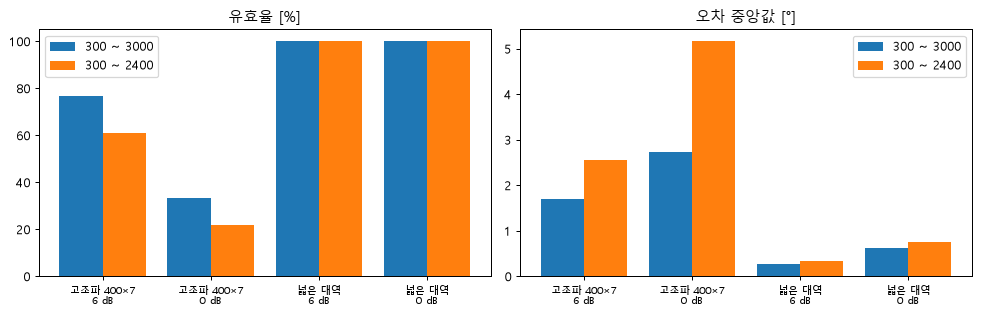

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
lab = [f"{r['source']}\n{r['snr']} dB" for r in rows7[::2]]
xx = np.arange(len(lab))
for k, (key, name) in enumerate((("valid", "유효율 [%]"), ("err_med", "오차 중앙값 [°]"))):
    ax[k].bar(xx - .2, [r[key] for r in rows7[::2]], .4, label="300 ~ 3000")
    ax[k].bar(xx + .2, [r[key] for r in rows7[1::2]], .4, label="300 ~ 2400")
    ax[k].set_xticks(xx, lab, fontsize=8); ax[k].set_title(name); ax[k].legend()
plt.tight_layout(); plt.show()

**읽는 법:** 2450 Hz 위의 2800 Hz 선을 빼면 고조파 음원에서 유효율이 떨어지고 오차가 커지는지 본다. 넓은 대역은 거의 변하지 않아야 한다.
그 이유는 3절 그림에 있다: 2800 Hz 칸은 감기긴 해도 정답 지연에서 다른 선들과 **같이 동의**하고, 감겨서 생긴 엉뚱한 지연에는 다른 선들이 동의하지 않는다. 그래서 가장 뾰족한 칸이 빠지는 손해가 더 크다.

## 8. 질문 2 — 투표하는 칸 고르기 (`full` / `line` / `oracle`)

> ▶ **예측 지점 (T1)**

대역 300 ~ 3000, 12방향 × 8 s, SNR 12 / 6 / 0 dB. 몇 분 걸린다.

In [10]:
rows8 = mp.sweep()
table(rows8, ["source", "snr", "method", "bins", "min_peak", "valid", "err_med", "err_p95", "wrong"],
      ["음원", "SNR", "방법", "쓴칸", "최소피크", "유효율%", "오차중앙°", "p95°", "유효중오답%"])

음원       | SNR      | 방법       | 쓴칸       | 최소피크     | 유효율%     | 오차중앙°    | p95°     | 유효중오답%  
고조파 400×7 | 12       | full     | 221.00   | 0.20     | 100.00   | 0.62     | 1.77     | 0.00    
고조파 400×7 | 12       | line     | 40.00    | 0.96     | 100.00   | 0.12     | 0.40     | 0.00    
고조파 400×7 | 12       | oracle   | 35.00    | 0.93     | 100.00   | 0.17     | 0.53     | 0.00    
고조파 400×7 | 6        | full     | 221.00   | 0.19     | 76.88    | 1.71     | 4.96     | 0.35    
고조파 400×7 | 6        | line     | 30.00    | 0.98     | 100.00   | 0.23     | 0.74     | 0.00    
고조파 400×7 | 6        | oracle   | 35.00    | 0.92     | 100.00   | 0.35     | 1.15     | 0.00    
고조파 400×7 | 0        | full     | 221.00   | 0.16     | 33.33    | 2.74     | 10.26    | 6.45    
고조파 400×7 | 0        | line     | 8.00     | 0.99     | 99.73    | 0.49     | 1.59     | 0.00    
고조파 400×7 | 0        | oracle   | 35.00    | 0.89     | 100.00   | 0.70     | 2.47     | 0.00    
고조파 700×4 | 12       

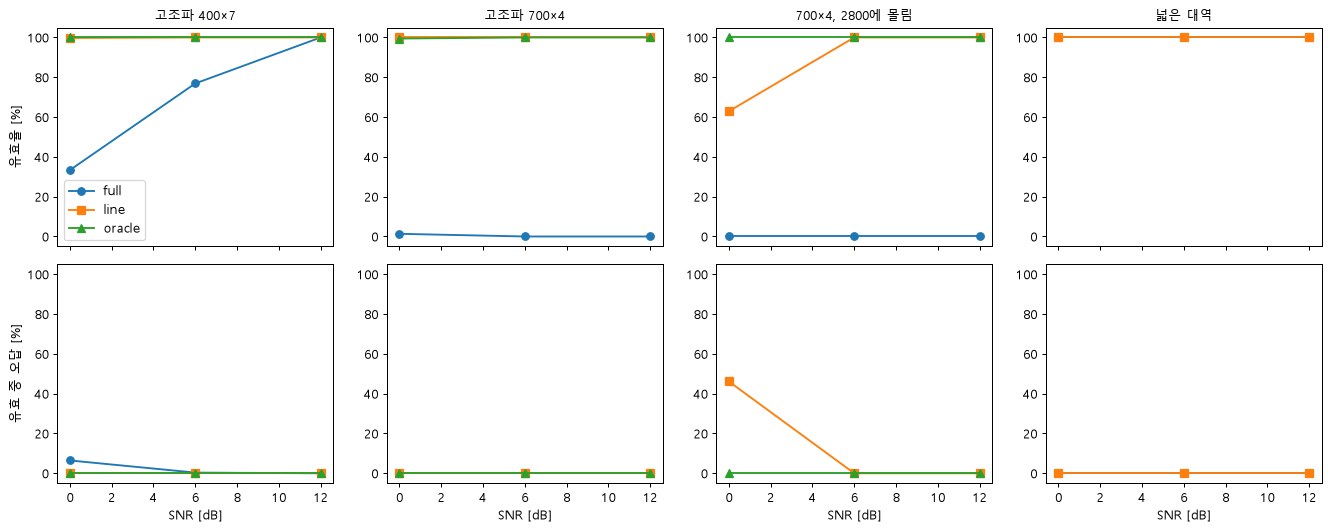

In [11]:
srcs = list(mp.SOURCES)
fig, ax = plt.subplots(2, len(srcs), figsize=(15, 6), sharex=True)
for c, s in enumerate(srcs):
    for m, mk in (("full", "o-"), ("line", "s-"), ("oracle", "^-")):
        rr = [r for r in rows8 if r["source"] == s and r["method"] == m]
        if not rr: continue
        ax[0, c].plot([r["snr"] for r in rr], [r["valid"] for r in rr], mk, label=m)
        ax[1, c].plot([r["snr"] for r in rr], [r["wrong"] for r in rr], mk, label=m)
    ax[0, c].set_title(s, fontsize=10); ax[0, c].set_ylim(-5, 105); ax[1, c].set_ylim(-5, 105)
    ax[1, c].set_xlabel("SNR [dB]")
ax[0, 0].set_ylabel("유효율 [%]"); ax[1, 0].set_ylabel("유효 중 오답 [%]"); ax[0, 0].legend()
plt.tight_layout(); plt.show()

## 9. 위험 사례 — 유효로 통과했는데 방향이 틀린 창

`700×4, 2800에 몰림`, SNR 0 dB, `line`에서 유효 중 오답이 생긴다. 그런 창 하나를 골라 들여다본다.

- 위: 스펙트럼과 선 마스크가 고른 칸 (2450 Hz 위가 몇 칸인지)
- 아래: 세 쌍의 상관 곡선. 점선 = 정답 지연, 빨간 점 = 고른 봉우리

정답 0°, 추정 -179.6°, 고른 칸 5개 중 2450 Hz 위 5개, 피크 [0.98 0.98 0.98], 닫힘 +0.005, norm 1.03


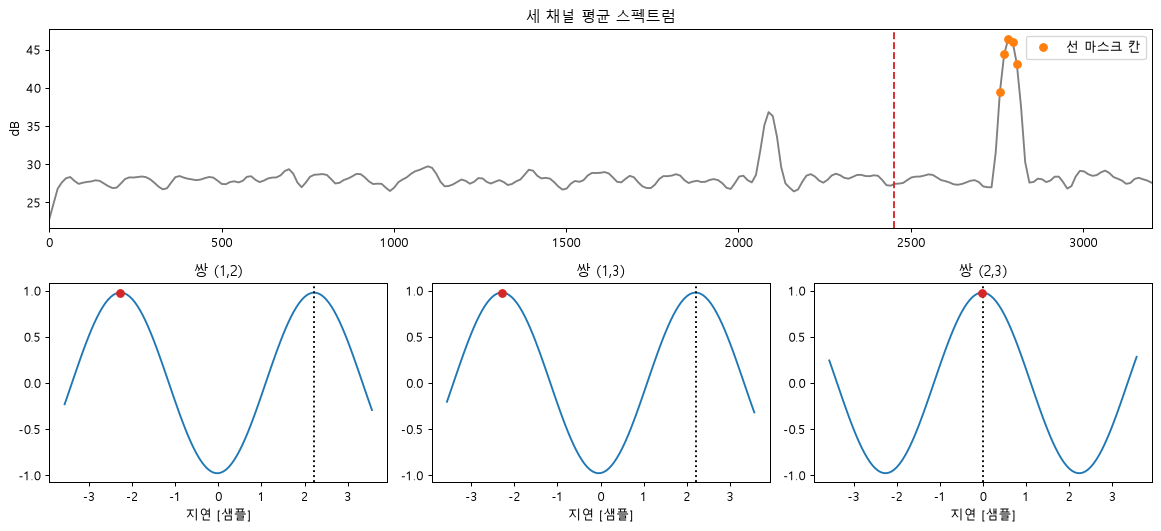

In [12]:
found = None
for i, az in enumerate(range(0, 360, 30)):
    x = mp.make_scene("700×4, 2800에 몰림", az, 0, seed=7 + i)
    for s0 in range(0, x.shape[1] - 6250 + 1, 3125):
        r = mp.estimate(x[:, s0:s0 + 6250], "line", 700, keep=True)
        if r["valid"] and ds.ang_err(r["angle"], az) > 10:
            found = (az, s0, r); break
    if found: break
az, s0, r = found
m = r["mask"]
print(f"정답 {az}°, 추정 {r['angle']:.1f}°, 고른 칸 {m.sum()}개 중 2450 Hz 위 {int((m & (mp.FREQ > mp.F_ALIAS)).sum())}개, "
      f"피크 {np.round(r['peak'], 2)}, 닫힘 {r['closure']:+.3f}, norm {r['norm']:.2f}")
fig = plt.figure(figsize=(13, 6))
a0 = fig.add_subplot(2, 1, 1)
P = sum(r["S"][3 + c] for c in range(3)).real
a0.plot(mp.FREQ, 10*np.log10(P), color="0.5"); a0.plot(mp.FREQ[m], 10*np.log10(P[m]), "o", color="C1", label="선 마스크 칸"); a0.set_ylabel("dB")
a0.axvline(mp.F_ALIAS, color="C3", ls="--"); a0.set_xlim(0, 3200); a0.legend(); a0.set_title("세 채널 평균 스펙트럼")
for k in range(3):
    a = fig.add_subplot(2, 3, 4 + k)
    lags, cc, tau, pk = r["curves"][k]
    a.plot(lags, cc); a.axvline(mp.true_tau(az)[k], color="k", ls=":"); a.plot(tau, pk, "o", color="C3")
    i, j = g.PAIRS[k]; a.set_title(f"쌍 ({i+1},{j+1})"); a.set_xlabel("지연 [샘플]")
plt.tight_layout(); plt.show()

**보이는 것:** 투표하는 칸이 거의 2800 Hz 선 하나라면, 그 선이 감겨서 만든 엉뚱한 봉우리를 눌러 줄 다른 선이 없다. 투표한 칸이 모두 같은 엉뚱한 지연에 동의하니 피크가 높고, 세 쌍이 함께 틀리면 닫힘도 통과할 수 있다.
→ 마스크를 쓰면 **피크 문턱은 더 이상 거르는 역할을 못 한다** (고른 칸끼리의 일치도라서 거의 항상 높다).

## 10. 결론 후보 (사용자 확인 전)

아래는 AI가 위 셀들에서 읽은 **후보**다. 사용자가 그림과 표를 직접 확인한 뒤 결정(T2)으로 올린다. 숫자는 바로 아래 셀이 위 결과에서 다시 뽑는다.

1. **대역 상한은 3000을 유지한다** — 7절: 2400으로 내리면 고조파 음원이 나빠지고 넓은 대역은 그대로.
2. **고조파 음원이 무효가 되는 주원인은 피크 문턱이다** — 4·8절: `full`은 선이 적을수록 봉우리가 낮아 SNR이 높아도 문턱 0.15에 걸린다.
3. **고조파 칸만 투표시키면 유효율과 오차가 크게 좋아진다** — 8절 `line`·`oracle`.
4. **대신 새 안전장치가 필요하다** — 9절: 마스크가 2450 Hz 위 선에 몰리면 틀린 방향이 유효로 통과한다. `oracle`(f0 배수를 다 넣음)은 같은 조건에서 괜찮았다.

**아직 모르는 것:** 반사·배경의 선(팬, 전원 험)·채널 간 상관 잡음이 있는 실제 녹음에서도 같은가 (다른 PC의 실녹음으로 확인). 고조파 센서(Step8b)의 실제 f0 추정으로 `oracle`을 대신하면 얼마나 남는가.

In [13]:
def pick(rows, **kw):
    return next(r for r in rows if all(r[k] == v for k, v in kw.items()))
a, b = pick(rows7, source="고조파 400×7", snr=6, band="300 ~ 3000"), pick(rows7, source="고조파 400×7", snr=6, band="300 ~ 2400")
print(f"후보 1: 고조파 400×7, 6 dB — 유효율 {a['valid']:.0f}% → {b['valid']:.0f}%, 오차 중앙 {a['err_med']:.2f}° → {b['err_med']:.2f}°")
f = pick(rows8, source="고조파 700×4", snr=12, method="full")
print(f"후보 2: 고조파 700×4, 12 dB, full — 최소 피크 중앙 {f['min_peak']:.2f} (문턱 0.15), 유효율 {f['valid']:.0f}%")
for m in ("full", "line", "oracle"):
    r = pick(rows8, source="고조파 400×7", snr=0, method=m)
    print(f"후보 3: 고조파 400×7, 0 dB, {m:6s} — 유효율 {r['valid']:.0f}%, 오차 중앙 {r['err_med']:.2f}°")
for m in ("line", "oracle"):
    r = pick(rows8, source="700×4, 2800에 몰림", snr=0, method=m)
    print(f"후보 4: 2800에 몰림, 0 dB, {m:6s} — 유효율 {r['valid']:.0f}%, 유효 중 오답 {r['wrong']:.0f}%")

후보 1: 고조파 400×7, 6 dB — 유효율 77% → 61%, 오차 중앙 1.71° → 2.56°
후보 2: 고조파 700×4, 12 dB, full — 최소 피크 중앙 0.12 (문턱 0.15), 유효율 0%
후보 3: 고조파 400×7, 0 dB, full   — 유효율 33%, 오차 중앙 2.74°
후보 3: 고조파 400×7, 0 dB, line   — 유효율 100%, 오차 중앙 0.49°
후보 3: 고조파 400×7, 0 dB, oracle — 유효율 100%, 오차 중앙 0.70°
후보 4: 2800에 몰림, 0 dB, line   — 유효율 63%, 유효 중 오답 46%
후보 4: 2800에 몰림, 0 dB, oracle — 유효율 100%, 유효 중 오답 0%
